# Gayrimenkul Fiyat Tahmini

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
df=pd.read_csv('Real_Estate.csv')

In [3]:
df.head()

,Transaction date,House age,Distance to the nearest MRT station,Number of convenience stores,Latitude,Longitude,House price of unit area
0,2012-09-02 16:42:30.519336,13.3,4082.0150,8,25.007059,121.561694,6.488673
1,2012-09-04 22:52:29.919544,35.5,274.0144,2,25.012148,121.546990,24.970725
2,2012-09-05 01:10:52.349449,1.1,1978.6710,10,25.003850,121.528336,26.694267
3,2012-09-05 13:26:01.189083,22.2,1055.0670,5,24.962887,121.482178,38.091638
4,2012-09-06 08:29:47.910523,8.5,967.4000,6,25.011037,121.479946,21.654710


In [4]:

df['Transaction date'] = pd.to_datetime(df['Transaction date'])


df['Transaction_year'] = df['Transaction date'].dt.year
df['Transaction_month'] = df['Transaction date'].dt.month


df = df.drop('Transaction date', axis=1)


In [5]:
df.shape

(414, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   House age                            414 non-null    float64
 1   Distance to the nearest MRT station  414 non-null    float64
 2   Number of convenience stores         414 non-null    int64  
 3   Latitude                             414 non-null    float64
 4   Longitude                            414 non-null    float64
 5   House price of unit area             414 non-null    float64
 6   Transaction_year                     414 non-null    int32  
 7   Transaction_month                    414 non-null    int32  
dtypes: float64(5), int32(2), int64(1)
memory usage: 22.8 KB


In [7]:
df.isna().sum()

House age                              0
Distance to the nearest MRT station    0
Number of convenience stores           0
Latitude                               0
Longitude                              0
House price of unit area               0
Transaction_year                       0
Transaction_month                      0
dtype: int64

In [8]:
df.describe()

,House age,Distance to the nearest MRT station,Number of convenience stores,Latitude,Longitude,House price of unit area,Transaction_year,Transaction_month
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,18.405072,1064.468233,4.265700,24.973605,121.520268,29.102149,2012.630435,6.381643
std,11.757670,1196.749385,2.880498,0.024178,0.026989,15.750935,0.483271,3.580855
min,0.000000,23.382840,0.000000,24.932075,121.473888,0.000000,2012.000000,1.000000
25%,9.900000,289.324800,2.000000,24.952422,121.496866,18.422493,2012.000000,3.000000
50%,16.450000,506.114400,5.000000,24.974353,121.520912,30.394070,2013.000000,6.000000
75%,30.375000,1454.279000,6.750000,24.994947,121.544676,40.615184,2013.000000,10.000000
max,42.700000,6306.153000,10.000000,25.014578,121.565321,65.571716,2013.000000,12.000000


In [9]:
df.corr(numeric_only=True)

,House age,Distance to the nearest MRT station,Number of convenience stores,Latitude,Longitude,House price of unit area,Transaction_year,Transaction_month
House age,1.000000,0.021596,0.021973,0.114345,0.036449,-0.012284,-0.025535,0.018921
Distance to the nearest MRT station,0.021596,1.000000,0.069015,0.038954,0.064229,-0.636579,-0.017002,0.027954
Number of convenience stores,0.021973,0.069015,1.000000,0.082725,0.013156,0.280763,-0.096270,0.081461
Latitude,0.114345,0.038954,0.082725,1.000000,0.007754,0.081008,0.024791,-0.050891
Longitude,0.036449,0.064229,0.013156,0.007754,1.000000,-0.098626,0.086737,-0.057595
House price of unit area,-0.012284,-0.636579,0.280763,0.081008,-0.098626,1.000000,0.015745,-0.041256
Transaction_year,-0.025535,-0.017002,-0.096270,0.024791,0.086737,0.015745,1.000000,-0.873938
Transaction_month,0.018921,0.027954,0.081461,-0.050891,-0.057595,-0.041256,-0.873938,1.000000


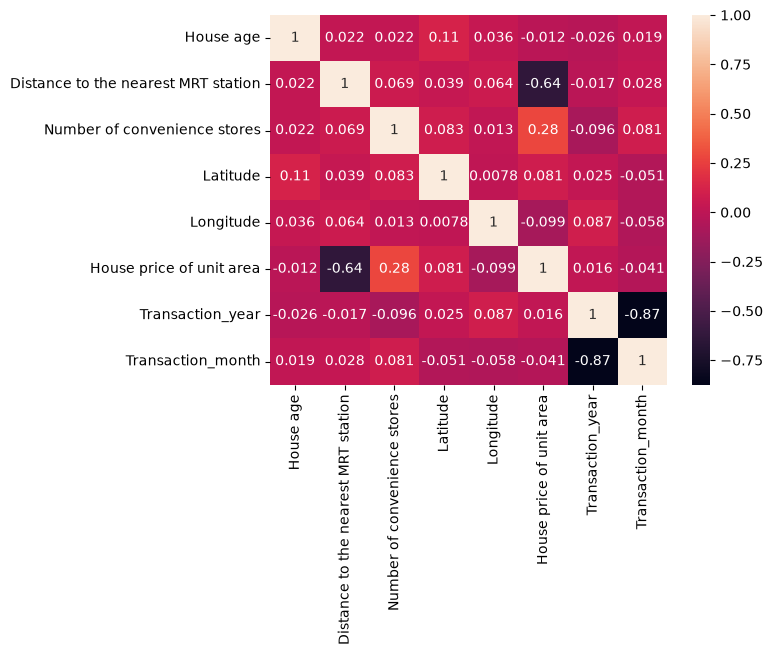

In [10]:
sns.heatmap(df.corr(numeric_only=True),annot=True);

In [11]:
import matplotlib.pyplot as plt


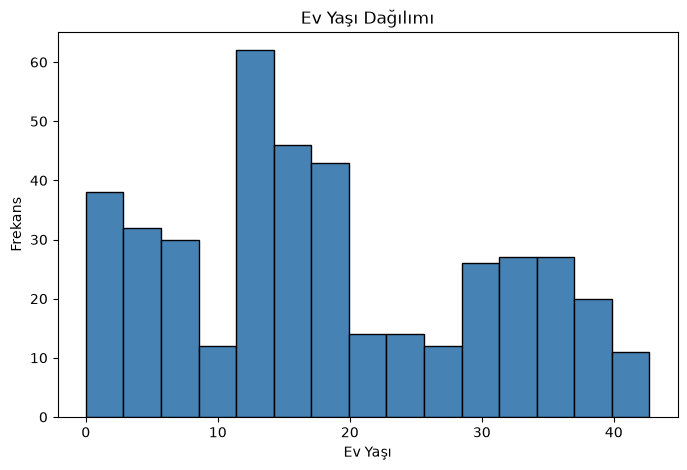

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['House age'], bins=15, color='steelblue', edgecolor='black')

plt.title('Ev Yaşı Dağılımı')
plt.xlabel('Ev Yaşı')
plt.ylabel('Frekans')
plt.show()


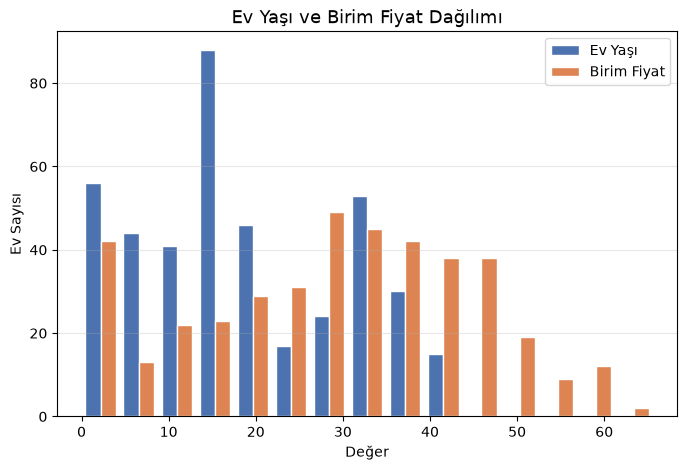

In [13]:
import matplotlib.pyplot as plt

m = df['House age']
w = df['House price of unit area']

plt.figure(figsize=(8, 5))

# İki veriyi yan yana çubuklar halinde, yumuşak renklerle çizdirme
plt.hist([m, w], bins=15, color=['#4C72B0', '#DD8452'], edgecolor='white', label=['Ev Yaşı', 'Birim Fiyat'])

plt.title('Ev Yaşı ve Birim Fiyat Dağılımı', fontsize=13)
plt.xlabel('Değer')
plt.ylabel('Ev Sayısı')
plt.legend() # Hangi rengin ne olduğunu gösterir
plt.grid(axis='y', alpha=0.3) # Hafif arka plan çizgileri

plt.show()


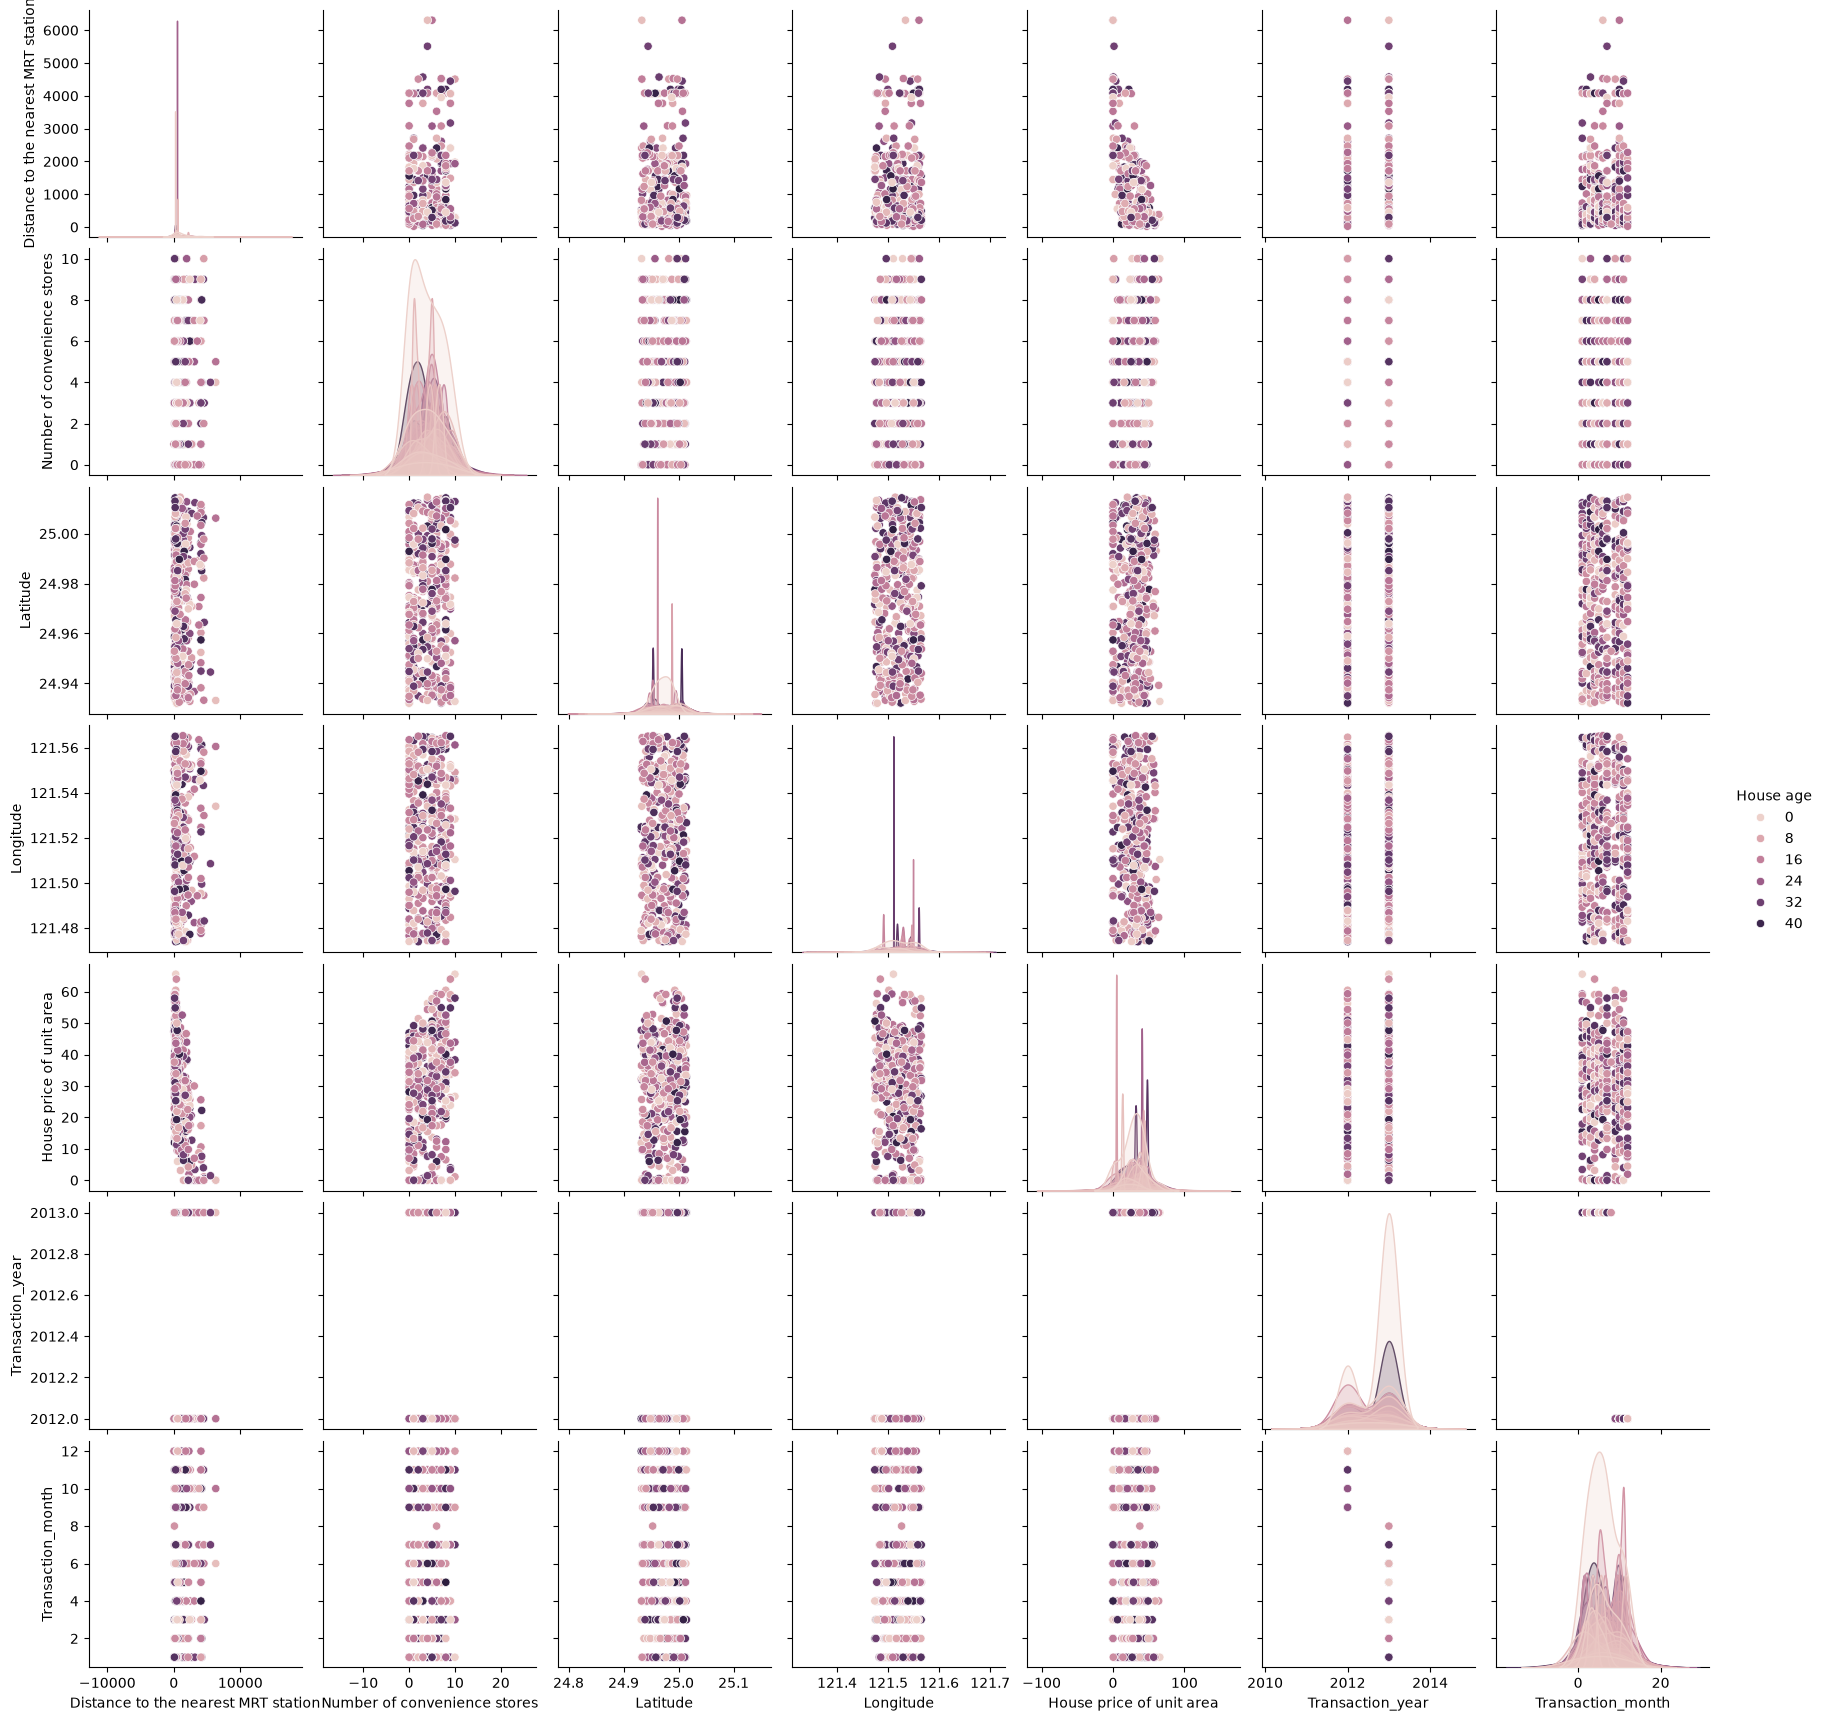

In [14]:
sns.pairplot(df,hue='House age');

In [15]:
df.columns

Index(['House age', 'Distance to the nearest MRT station',
       'Number of convenience stores', 'Latitude', 'Longitude',
       'House price of unit area', 'Transaction_year', 'Transaction_month'],
      dtype='str')

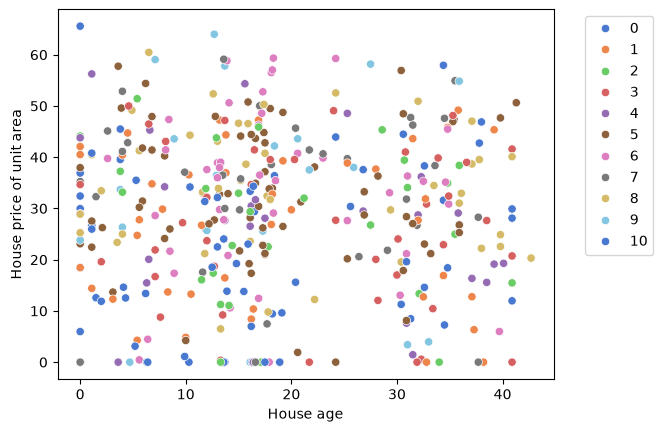

In [16]:
sns.scatterplot(x=df['House age'],y=df['House price of unit area'], hue=df['Number of convenience stores'], palette='muted')
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left');

In [17]:
from scipy.stats import ttest_ind

In [18]:
t,p=ttest_ind(df['House age'],df['Number of convenience stores'])
float(p)  # p degerini bulma 

1.517378425403324e-95

In [19]:
p<0.05

np.True_

In [20]:
abs(df.corr(numeric_only=True))['House price of unit area'].sort_values(ascending=False)

House price of unit area               1.000000
Distance to the nearest MRT station    0.636579
Number of convenience stores           0.280763
Longitude                              0.098626
Latitude                               0.081008
Transaction_month                      0.041256
Transaction_year                       0.015745
House age                              0.012284
Name: House price of unit area, dtype: float64

In [74]:
x = df.drop('House price of unit area',axis=1)
y = df['House price of unit area']

In [75]:
from sklearn.model_selection import train_test_split

In [76]:
from sklearn.preprocessing import MinMaxScaler

In [77]:
x=pd.get_dummies(x,drop_first=True)

In [78]:
x=MinMaxScaler().fit_transform(x)

In [79]:
x_train, x_test, y_train , y_test=train_test_split(x,y,  random_state=42, test_size=.20)

In [80]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error

# Linear / Regularized
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  SGDRegressor, HuberRegressor, RANSACRegressor,
                                  BayesianRidge, OrthogonalMatchingPursuit)
# Tree
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, AdaBoostRegressor)
# Neighbors
from sklearn.neighbors import KNeighborsRegressor
# SVR / Kernel
from sklearn.svm import SVR, NuSVR
from sklearn.kernel_ridge import KernelRidge
# Neural Net
from sklearn.neural_network import MLPRegressor
# Boosting
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Yellowbrick
from yellowbrick.regressor import PredictionError, ResidualsPlot

# Suppress warnings
warnings.filterwarnings("ignore")

def algo_test(x, y, plot=True, yellowbrick_viz=False):
    # ======================
    # Define Regression Models
    # ======================
    algos = [
        LinearRegression(),
        Ridge(),
        Lasso(),
        ElasticNet(),
        SGDRegressor(max_iter=1000, tol=1e-3),
        HuberRegressor(),
        RANSACRegressor(),
        BayesianRidge(),
        OrthogonalMatchingPursuit(),
        ExtraTreeRegressor(),
        DecisionTreeRegressor(),
        RandomForestRegressor(),
        GradientBoostingRegressor(),
        HistGradientBoostingRegressor(),
        AdaBoostRegressor(),
        XGBRegressor(verbosity=0, n_jobs=-1),
        CatBoostRegressor(verbose=0),
        KNeighborsRegressor(),
        SVR(),
        NuSVR(),
        KernelRidge(),
        MLPRegressor(max_iter=500, hidden_layer_sizes=(100,50))
    ]

    algo_names = [
        'Linear', 'Ridge', 'Lasso', 'ElasticNet', 'SGD', 
        'Huber', 'RANSAC', 'BayesianRidge', 'OMP',
        'Extra Tree', 'Decision Tree', 'Random Forest', 'Gradient Boosting',
        'HistGradientBoosting', 'AdaBoost', 'XGBoost', 'CatBoost',
        'KNN', 'SVR', 'NuSVR', 'KernelRidge', 'MLP'
    ]

    # ======================
    # Train/Test Split
    # ======================
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.20, random_state=42
    )

    results = []

    # ======================
    # Fit Models & Evaluate
    # ======================
    for name, algo in zip(algo_names, algos):
        try:
            # Scale only non-tree models
            if name not in ['Extra Tree', 'Decision Tree', 'Random Forest',
                            'Gradient Boosting', 'HistGradientBoosting',
                            'AdaBoost', 'XGBoost', 'CatBoost']:
                scaler = MinMaxScaler()
                x_train_scaled = scaler.fit_transform(x_train)
                x_test_scaled = scaler.transform(x_test)
            else:
                x_train_scaled = x_train
                x_test_scaled = x_test

            # Fit and predict
            preds = algo.fit(x_train_scaled, y_train).predict(x_test_scaled)
            r2 = r2_score(y_test, preds)
            rmse = np.sqrt(mean_squared_error(y_test, preds))
        except Exception as e:
            r2 = None
            rmse = None
            print(f"Model {name} failed: {e}")

        results.append({
            "Model": name,
            "R2": r2,
            "RMSE": rmse
        })

        # ======================
        # Yellowbrick visualizations
        # ======================
        if yellowbrick_viz:
            try:
                # Prediction Error
                plt.figure(figsize=(10, 6))
                visualizer = PredictionError(algo)
                visualizer.fit(x_train_scaled, y_train)
                visualizer.score(x_test_scaled, y_test)
                visualizer.show()

                # Residuals Plot
                plt.figure(figsize=(10, 6))
                visualizer = ResidualsPlot(algo)
                visualizer.fit(x_train_scaled, y_train)
                visualizer.score(x_test_scaled, y_test)
                visualizer.show()

            except Exception as e:
                print(f"Yellowbrick visualizations for {name} failed: {e}")

    # ======================
    # Results Table
    # ======================
    result_df = pd.DataFrame(results).sort_values("R2", ascending=False)
    
    print("\n=== Regression Model Comparison ===\n")
    print(result_df.reset_index(drop=True))

    # ======================
    # Seaborn Plots
    # ======================
    if plot:
        plt.figure(figsize=(18, 7))

        # R2 Score
        plt.subplot(1, 2, 1)
        sns.barplot(data=result_df, x="Model", y="R2", palette="viridis")
        plt.title("R² Score Comparison (Higher is Better)")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis="y", alpha=0.3)

        # RMSE
        plt.subplot(1, 2, 2)
        sns.barplot(data=result_df, x="Model", y="RMSE", palette="magma")
        plt.title("RMSE Comparison (Lower is Better)")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()

        # RMSE vs R2 scatter
        plt.figure(figsize=(12, 6))
        sns.scatterplot(data=result_df, x="RMSE", y="R2", hue="Model", s=150)
        for i, row in result_df.iterrows():
            plt.text(row["RMSE"], row["R2"], row["Model"], fontsize=9)
        plt.title("Regression Model Trade-off: RMSE vs R²")
        plt.xlabel("RMSE (Lower is Better)")
        plt.ylabel("R² (Higher is Better)")
        plt.grid(alpha=0.3)
        plt.show()

    return result_df



=== Regression Model Comparison ===

                   Model        R2       RMSE
0                    MLP  0.541891  11.257542
1                    SGD  0.537743  11.308395
2                 Linear  0.529615  11.407382
3          Random Forest  0.528846  11.416701
4          BayesianRidge  0.527226  11.436313
5                  Ridge  0.519683  11.527178
6                  Huber  0.516954  11.559885
7               AdaBoost  0.498992  11.772848
8            KernelRidge  0.477416  12.023674
9      Gradient Boosting  0.474341  12.058994
10                   OMP  0.464028  12.176714
11              CatBoost  0.438244  12.466171
12  HistGradientBoosting  0.424927  12.613060
13                   KNN  0.390383  12.986369
14               XGBoost  0.376914  13.129043
15                 Lasso  0.325727  13.657686
16                RANSAC  0.303027  13.885681
17         Decision Tree  0.221282  14.677404
18                   SVR  0.213989  14.745975
19                 NuSVR  0.197886  14.896

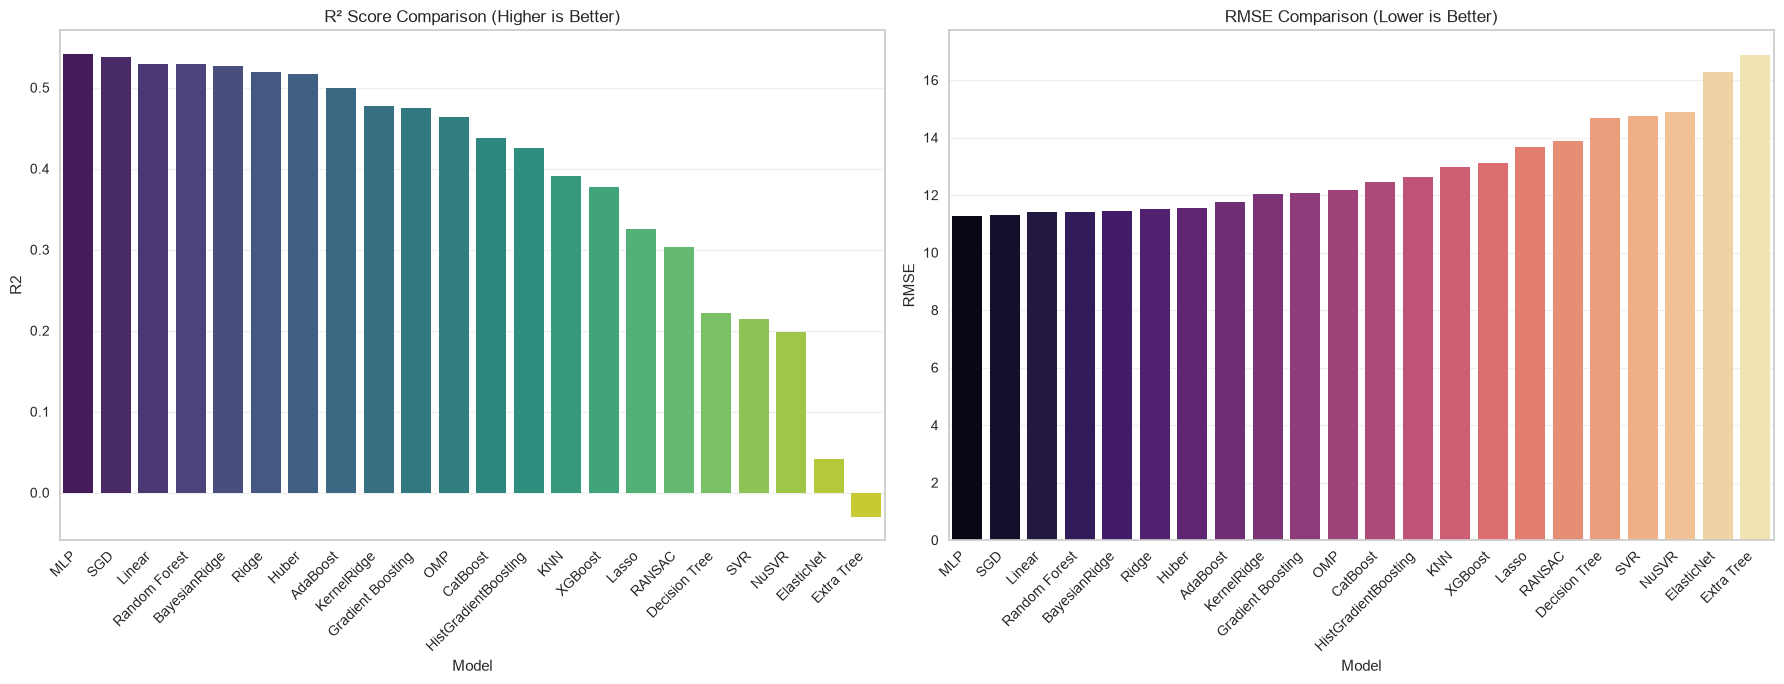

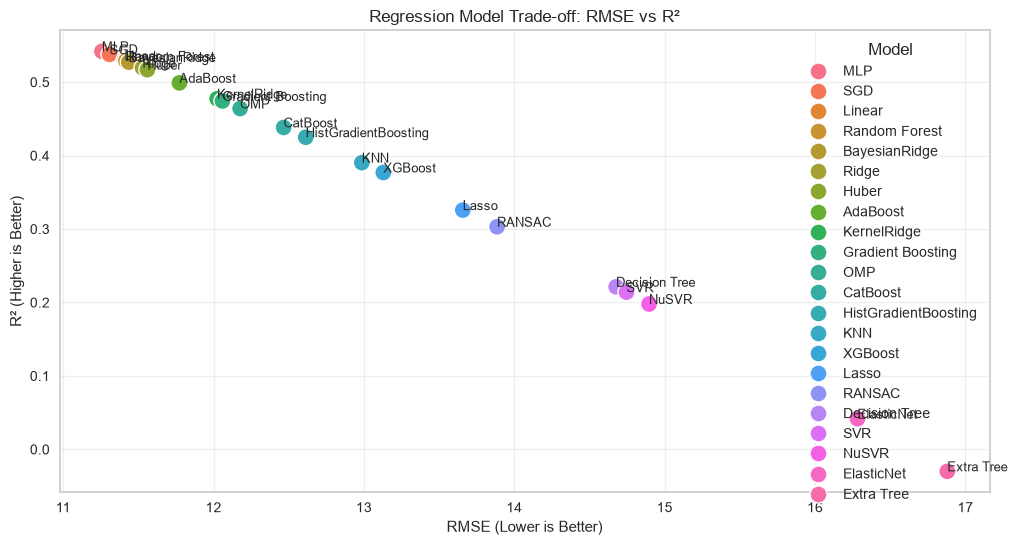

,Model,R2,RMSE
21,MLP,0.541891,11.257542
4,SGD,0.537743,11.308395
0,Linear,0.529615,11.407382
11,Random Forest,0.528846,11.416701
7,BayesianRidge,0.527226,11.436313
1,Ridge,0.519683,11.527178
5,Huber,0.516954,11.559885
14,AdaBoost,0.498992,11.772848
20,KernelRidge,0.477416,12.023674
12,Gradient Boosting,0.474341,12.058994


In [81]:
algo_test(x,y)

In [ ]:
import os, pickle

if os.path.exists("emlak1.pkl"):
    yuklenen = pickle.load(open("emlak.pkl", "rb"))
    print("Başarıyla kaydedilmiş! Dosya boyutu:", os.path.getsize("emlak.pkl"), "byte")
    print("İçerik:", yuklenen)
else:
    print("Hata: emlak.pkl dosyası bulunamadı!")

In [95]:
print(model.n_features_in_)
print(x_train.shape)
print(x_test.shape)

2
(331, 7)
(83, 7)


In [82]:
lr=LinearRegression()

In [83]:
lr.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ -0.64,-54.27, 17.73,..., -3.37, -0.49, -2.99]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,32.16
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[11.55, 6.31, 5.97,..., 5.34, 3.84, 2.73]"


In [84]:
tahmin=lr.predict (x_test)

In [85]:
sonuc=pd.DataFrame()

In [86]:
sonuc['House price of unit area']=tahmin

In [87]:
sonuc['Gercek_Deger'] = y_test.values

In [88]:
sonuc.head()

,House price of unit area,Gercek_Deger
0,38.623640,35.762667
1,30.419706,31.743662
2,30.883081,27.786894
3,44.515413,54.831664
4,22.831486,39.416482


In [92]:
import pickle
pickle.dump(model, open("emlak1.pkl", "wb"))


In [93]:
import os, pickle

if os.path.exists("emlak1.pkl"):
    yuklenen = pickle.load(open("emlak.pkl", "rb"))
    print("Başarıyla kaydedilmiş! Dosya boyutu:", os.path.getsize("emlak.pkl"), "byte")
    print("İçerik:", yuklenen)
else:
    print("Hata: emlak.pkl dosyası bulunamadı!")


Başarıyla kaydedilmiş! Dosya boyutu: 499 byte
İçerik: LinearRegression()


In [94]:
print(model.n_features_in_)
print(model.feature_names_in_)

2


AttributeError: 'LinearRegression' object has no attribute 'feature_names_in_'